<a href="https://colab.research.google.com/github/mkaabduljaleelhinan-pixel/restaurant-review-sentiment-analysis/blob/main/zomato_restaurants_reviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving zomato.csv to zomato (1).csv


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("zomato.csv")
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
df.head()

Dataset loaded successfully!
Number of rows and columns: (51717, 17)


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [5]:
print("Column names:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDataset information:")
df.info()

Column names:
['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']

Missing values:
url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 517

In [6]:
print("Missing values before cleaning:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values before cleaning:
url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

Total missing values: 37700


In [7]:
df_clean = df.copy()
df_clean = df_clean.dropna(subset=["reviews_list"])
df_clean = df_clean[
    df_clean["reviews_list"].astype(str).str.strip().ne("")
].copy()
print("Original restaurant records:", len(df))
print("Records after cleaning:", len(df_clean))
print(
    "Missing review lists remaining:",
    df_clean["reviews_list"].isnull().sum()
)

Original restaurant records: 51717
Records after cleaning: 51717
Missing review lists remaining: 0


In [10]:

reviews_df = reviews_df.dropna(
    subset=["review", "rating"]
).copy()
reviews_df = reviews_df[
    reviews_df["review"].str.strip().ne("")
].copy()
reviews_df = reviews_df.drop_duplicates(
    subset=["review", "rating"]
).reset_index(drop=True)

print("Usable reviews after cleaning:", len(reviews_df))
print("\nMissing values:")
print(reviews_df.isnull().sum())

print("\nCleaned sample:")
print(reviews_df.head())

Usable reviews after cleaning: 69646

Missing values:
review    0
rating    0
dtype: int64

Cleaned sample:
                                              review  rating
0  rated a beautiful place to dine in the interio...     4.0
1  rated i was here for dinner with my family on ...     4.0
2  rated its a restaurant near to banashankari bd...     2.0
3  rated we went here on a weekend and one of us ...     4.0
4  rated the best thing about the place is it s a...     5.0


In [9]:
import ast
import re
import html
import pandas as pd

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

def extract_reviews(value):
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(value)
    except (ValueError, SyntaxError, TypeError):
        return []
    if not isinstance(parsed, (list, tuple)):
        return []
    extracted = []
    for item in parsed:
        if not isinstance(item, (list, tuple)) or len(item) < 2:
            continue
        rating_text = str(item[0])
        review_text = item[1]
        match = re.search(r"(\d+(?:\.\d+)?)", rating_text)
        if not match or pd.isna(review_text):
            continue
        rating = float(match.group(1))
        if not 1 <= rating <= 5:
            continue
        review = clean_text(review_text)
        if len(review.split()) < 3:
            continue
        extracted.append({
            "review": review,
            "rating": rating
        })
    return extracted

records = []
# Let's subset to 15,000 records to speed up processing and prevent hanging
for value in df_clean["reviews_list"].head(15000):
    records.extend(extract_reviews(value))

reviews_df = pd.DataFrame(
    records,
    columns=["review", "rating"]
)

print("Total extracted reviews:", len(reviews_df))
display(reviews_df.head(10))

Total extracted reviews: 311384


,review,rating
0,rated a beautiful place to dine in the interio...,4.0
1,rated i was here for dinner with my family on ...,4.0
2,rated its a restaurant near to banashankari bd...,2.0
3,rated we went here on a weekend and one of us ...,4.0
4,rated the best thing about the place is it s a...,5.0
5,rated great food and pleasant ambience expensi...,5.0
6,rated good ambience with tasty food cheese chi...,4.0
7,rated you can t go wrong with jalsa never been...,4.0
8,rated overdelighted by the service and food pr...,5.0
9,rated the place is nice and comfortable food w...,4.0


In [11]:

def classify_sentiment(rating):
    if rating >= 4.0:
        return 1
    elif rating <= 2.0:
        return 0
    else:
        return None


reviews_df["sentiment"] = reviews_df["rating"].apply(
    classify_sentiment
)
reviews_df = reviews_df.dropna(
    subset=["sentiment"]
).copy()

reviews_df["sentiment"] = (
    reviews_df["sentiment"].astype(int)
)

print("Final number of labeled reviews:", len(reviews_df))

print("\nSentiment distribution:")
print(
    reviews_df["sentiment"]
    .value_counts()
    .rename(index={0: "Negative", 1: "Positive"})
)

print("\nSample labeled reviews:")
print(reviews_df[["review", "rating", "sentiment"]].head(10))

Final number of labeled reviews: 55542

Sentiment distribution:
sentiment
Positive    40817
Negative    14725
Name: count, dtype: int64

Sample labeled reviews:
                                              review  rating  sentiment
0  rated a beautiful place to dine in the interio...     4.0          1
1  rated i was here for dinner with my family on ...     4.0          1
2  rated its a restaurant near to banashankari bd...     2.0          0
3  rated we went here on a weekend and one of us ...     4.0          1
4  rated the best thing about the place is it s a...     5.0          1
5  rated great food and pleasant ambience expensi...     5.0          1
6  rated good ambience with tasty food cheese chi...     4.0          1
7  rated you can t go wrong with jalsa never been...     4.0          1
8  rated overdelighted by the service and food pr...     5.0          1
9  rated the place is nice and comfortable food w...     4.0          1


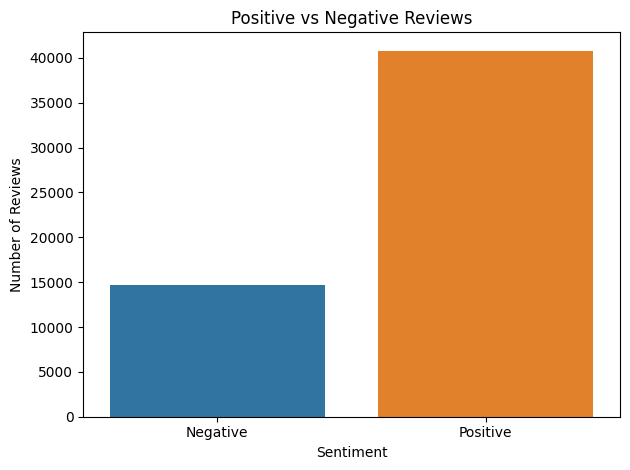

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=reviews_df,
    x="sentiment",
    hue="sentiment",
    legend=False
)

plt.xticks([0, 1], ["Negative", "Positive"])
plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [13]:

print("Total labeled reviews:", len(reviews_df))
print("\nColumns:", reviews_df.columns.tolist())
print("\nSentiment distribution:")
print(reviews_df["sentiment"].value_counts())

reviews_df.head()

Total labeled reviews: 55542

Columns: ['review', 'rating', 'sentiment']

Sentiment distribution:
sentiment
1    40817
0    14725
Name: count, dtype: int64


,review,rating,sentiment
0,rated a beautiful place to dine in the interio...,4.0,1
1,rated i was here for dinner with my family on ...,4.0,1
2,rated its a restaurant near to banashankari bd...,2.0,0
3,rated we went here on a weekend and one of us ...,4.0,1
4,rated the best thing about the place is it s a...,5.0,1


In [14]:

from sklearn.model_selection import train_test_split

SEED = 42

X = reviews_df["review"].astype(str).values
y = reviews_df["sentiment"].astype(int).values
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_full
)

print("Training reviews:", len(X_train))
print("Validation reviews:", len(X_val))
print("Testing reviews:", len(X_test))

Training reviews: 39989
Validation reviews: 4444
Testing reviews: 11109


In [15]:

from tensorflow.keras.preprocessing.text import Tokenizer

MAX_WORDS = 20000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

print("Total unique words in training vocabulary:",
      len(tokenizer.word_index))

print("\nExample word encodings:")
for word, index in list(tokenizer.word_index.items())[:15]:
    print(word, ":", index)

Total unique words in training vocabulary: 32448

Example word encodings:
<OOV> : 1
the : 2
and : 3
a : 4
rated : 5
was : 6
to : 7
is : 8
i : 9
of : 10
food : 11
for : 12
good : 13
place : 14
it : 15


In [16]:

train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

print("Original review:")
print(X_train[0])

print("\nEncoded sequence:")
print(train_sequences[0])

Original review:
rated this is a great place to enjoy delicious bengali cuisines at a reasonable rate food is better than many well known top class bengali restaurants

Encoded sequence:
[5, 17, 8, 4, 43, 14, 7, 328, 91, 717, 1069, 48, 4, 241, 592, 11, 8, 147, 144, 196, 62, 992, 312, 1385, 717, 385]


In [17]:

from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 150

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    val_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train_pad.shape)
print("Validation data shape:", X_val_pad.shape)
print("Testing data shape:", X_test_pad.shape)

Training data shape: (39989, 150)
Validation data shape: (4444, 150)
Testing data shape: (11109, 150)


In [18]:

print("Example cleaned review:")
print(X_train[0])

print("\nPadded numerical sequence:")
print(X_train_pad[0])

print("\nCorresponding sentiment label:")
print("Positive" if y_train[0] == 1 else "Negative")

Example cleaned review:
rated this is a great place to enjoy delicious bengali cuisines at a reasonable rate food is better than many well known top class bengali restaurants

Padded numerical sequence:
[   5   17    8    4   43   14    7  328   91  717 1069   48    4  241
  592   11    8  147  144  196   62  992  312 1385  717  385    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0]

Corresponding sentiment label:
Pos

In [19]:

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Dense,
    Dropout,
    SpatialDropout1D
)
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [20]:

MAX_WORDS = 20000
MAX_LEN = 150

model = Sequential([
    # Convert word IDs into dense vectors
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128,
        mask_zero=True
    ),

    SpatialDropout1D(0.2),

    LSTM(64),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

print("LSTM model created successfully!")


LSTM model created successfully!


In [21]:

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
model.build(input_shape=(None, MAX_LEN))
model.summary()

In [22]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping


In [23]:

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)


Class weights: {0: 1.8859177513676664, 1: 0.6803858849150985}


In [24]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.9251 - loss: 0.2080 - val_accuracy: 0.9397 - val_loss: 0.1524
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9611 - loss: 0.1137 - val_accuracy: 0.9485 - val_loss: 0.1409
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9734 - loss: 0.0784 - val_accuracy: 0.9516 - val_loss: 0.1397
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9780 - loss: 0.0627 - val_accuracy: 0.9512 - val_loss: 0.1486
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9827 - loss: 0.0492 - val_accuracy: 0.8400 - val_loss: 0.8321
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9819 - loss: 0.0535 - val_accuracy: 0.9550 - val_loss: 0.1532
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9884 - loss: 0.0316 - val_accuracy: 0.9523 - val_loss: 0.1813
Epoch 8/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9902 - loss: 0.0287 - val_ac

In [25]:
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9781 - loss: 0.0625 - val_accuracy: 0.9462 - val_loss: 0.1453
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9822 - loss: 0.0495 - val_accuracy: 0.9417 - val_loss: 0.1627
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9863 - loss: 0.0386 - val_accuracy: 0.9530 - val_loss: 0.1806
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9870 - loss: 0.0351 - val_accuracy: 0.9523 - val_loss: 0.1799
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9887 - loss: 0.0311 - val_accuracy: 0.9541 - val_loss: 0.1951
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9910 - loss: 0.0265 - val_accuracy: 0.9435 - val_loss: 0.1846
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9924 - loss: 0.0234 - val_accuracy: 0.9516 - val_loss: 0.1835
Epoch 8/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9933 - loss: 0.0198 - val_accu

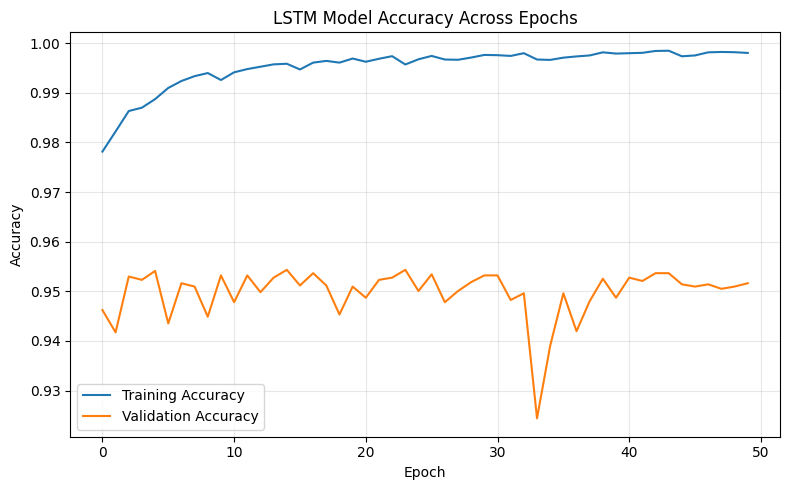

In [26]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Model Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


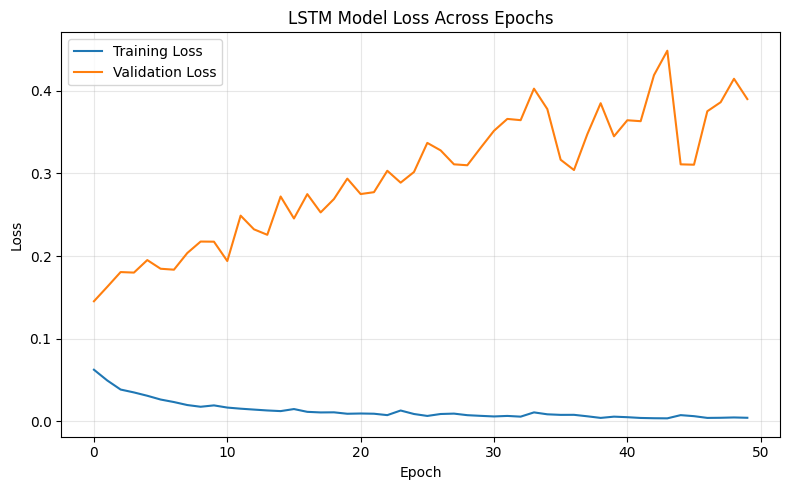

In [27]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Model Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:

model.save("zomato_lstm_sentiment.keras")

print("Trained model saved successfully!")


Trained model saved successfully!


In [29]:

from google.colab import files

files.download("zomato_lstm_sentiment.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [31]:

# Predict probabilities for the test reviews
y_prob = model.predict(X_test_pad, verbose=1).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= 0.5).astype(int)

print("Predictions completed!")
print("Number of test reviews:", len(y_test))


348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Predictions completed!
Number of test reviews: 11109


In [32]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("LSTM MODEL EVALUATION")
print("-" * 35)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")


LSTM MODEL EVALUATION
-----------------------------------
Accuracy  : 0.9536 (95.36%)
Precision : 0.9605
Recall    : 0.9770
F1-score  : 0.9687


In [33]:

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

    Negative       0.93      0.89      0.91      2945
    Positive       0.96      0.98      0.97      8164

    accuracy                           0.95     11109
   macro avg       0.95      0.93      0.94     11109
weighted avg       0.95      0.95      0.95     11109



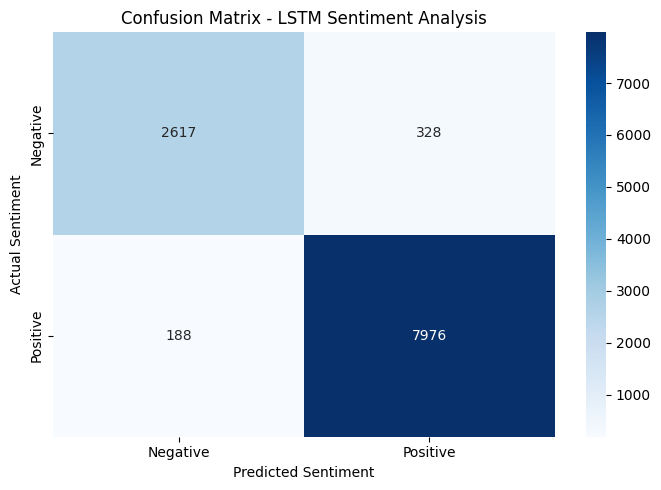

In [34]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix - LSTM Sentiment Analysis")
plt.tight_layout()
plt.show()


In [35]:

results = pd.DataFrame([{
    "Model": "LSTM",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}])

results.to_csv("zomato_lstm_evaluation.csv", index=False)

print(results)
print("\nEvaluation results saved.")

  Model  Accuracy  Precision    Recall  F1-score
0  LSTM  0.953551   0.960501  0.976972  0.968667

Evaluation results saved.


In [37]:

import numpy as np
import re
import html
import ipywidgets as widgets

from IPython.display import display, clear_output
from tensorflow.keras.preprocessing.sequence import pad_sequences


# Clean manually entered review text
def clean_user_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()


# Input area
review_input = widgets.Textarea(
    value="",
    placeholder="Enter your restaurant review here...",
    description="Review:",
    layout=widgets.Layout(width="100%", height="120px")
)

analyze_button = widgets.Button(
    description="Analyze Review",
    button_style="success",
    icon="search"
)

output = widgets.Output()


def analyze_review(button):
    with output:
        clear_output()

        raw_review = review_input.value.strip()

        if not raw_review:
            print("Please enter a restaurant review.")
            return

        cleaned_review = clean_user_review(raw_review)

        if not cleaned_review:
            print("Please enter a valid text review.")
            return

        # Tokenize using the same tokenizer used in training
        sequence = tokenizer.texts_to_sequences(
            [cleaned_review]
        )

        # Pad to the same length used during training
        padded = pad_sequences(
            sequence,
            maxlen=MAX_LEN,
            padding="post",
            truncating="post"
        )

        # Predict probability of positive sentiment
        probability = float(
            model.predict(padded, verbose=0)[0][0]
        )

        sentiment = (
            "Positive" if probability >= 0.5
            else "Negative"
        )

        print("=" * 45)
        print("       ZOMATO REVIEW ANALYZER")
        print("=" * 45)
        print("\nYour review:")
        print(raw_review)
        print("\nPredicted sentiment:", sentiment)
        print(
            "Positive probability: "
            f"{probability * 100:.2f}%"
        )
        print(
            "Negative probability: "
            f"{(1 - probability) * 100:.2f}%"
        )
        print("=" * 45)


analyze_button.on_click(analyze_review)

display(review_input, analyze_button, output)


Textarea(value='', description='Review:', layout=Layout(height='120px', width='100%'), placeholder='Enter your…

Button(button_style='success', description='Analyze Review', icon='search', style=ButtonStyle())

Output()